# ECE1512 Project A - Build an ABMIL training pipeline in PyTorch

This notebook uses pre-extracted whole-slide histopathology features and guides you through a complete PyTorch classification pipeline. The goal is not merely to run ABMIL; it is to understand the code path from data loading to optimization, validation, checkpoint selection, and final testing.

Please complete every cell marked `TODO`. Dataset engineering and metric boilerplate are provided so you can focus on the machine-learning training workflow.

This project requires basic familiarity with Python object-oriented programming (OOP). If you have limited experience with Python OOP, please review the provided introductory video before starting the project. 

[PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/introyt1_tutorial.html)

[Python Object-Oriented Programming ](https://www.youtube.com/watch?v=JeznW_7DlB0)

**Research extension:** Propose two research ideas and implement and evaluate one selected idea. Report ABMIL baseline and selected-extension results on **CAMELYON16, CAMELYON17, and BRACS**, using the same features and train/validation/test splits within each dataset. 

## Learning objectives

After this project you should be able to explain and implement:

1. `Dataset` vs. `DataLoader`, batching, shuffling.
2. `nn.Module`, trainable parameters, and `forward()`.
3. A classification loss and optimizer.
4. The training sequence `zero_grad -> forward -> loss -> backward -> step`.
5. The difference between `model.train()` and `model.eval()`.

## Step 0. Download Pre-extracted WSI Features & Select the Project Directory
Download the required feature file(s) from Zenodo or Hugging Face:

https://zenodo.org/records/23130543

https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature


Place the HDF5 file under the path expected by your YAML configuration in the `config/`, or edit data_dir in the YAML file.


In [ ]:
# %pip install -r requirements.txt

In [2]:
import os, sys, copy, time
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

torch.set_num_threads(4)

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


If you are using Google Colab with Drive, mount Drive first and change `PROJECT_DIR`.

In [ ]:
PROJECT_DIR = str(Path.cwd().resolve())
DATASET = 'C16'  # C16, C17, BRACS

if not (Path(PROJECT_DIR) / 'models.py').exists():
    raise RuntimeError('Set PROJECT_DIR to the Project_A_Starter_Code directory.')
    
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from run_experiments import load_project_config, CONFIGS
CONFIG_PATH = str(Path(PROJECT_DIR) / 'config' / CONFIGS[DATASET])

from wsi_visualization import visualize_wsi_attention

In [ ]:
from dataloader import build_HDF5_feat_dataset, mil_collate_fn
from utils import load_config, seed_everything, infer_feature_dim, classification_metrics

conf = load_project_config(DATASET, seed=42)
seed_everything(conf.seed)
print(conf)

if not Path(conf.data_dir).exists():
    raise FileNotFoundError('Download the official feature file first; see README.md.')

Struct(B=1, D_attn=128, D_feat=384, D_inner=256, data_dir='D:\\ECE1512H Digital Image Processing and Applications\\Project A\\Project_A_Starter_Code\\feature\\C16\\patch_feats_pretrain_medical_ssl.h5', dataset='CAMELYON16', dataset_csv_dir='D:\\ECE1512H Digital Image Processing and Applications\\Project A\\Project_A_Starter_Code\\dataset_csv', droprate=0.0, lr=0.0001, n_class=2, n_res=0, n_shot=0, n_worker=0, pin_memory=True, seed=42, train_epoch=30, val_fraction=0.1, warmup_epoch=3, wd=1e-05)


# Step 1 - Dataset and DataLoader

`build_HDF5_feat_dataset` is provided. It creates train/validation/test `Dataset` objects without loading all slide features into memory at once.


Complete the three `DataLoader` definitions. Think about which split should be shuffled.

[Download WSI datasets](https://zenodo.org/records/23130543)

[Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)


[PyTorch DataLoader](https://docs.pytorch.org/docs/2.14/data.html#torch.utils.data.DataLoader)


[PyTorch Datasets](https://docs.pytorch.org/vision/stable/datasets.html)


In [5]:
train_data, val_data, test_data = build_HDF5_feat_dataset(conf.data_dir, conf)
conf.D_feat = infer_feature_dim(train_data)
print('Split sizes: Train {}, Validation {}, Test {};'.format(len(train_data), len(val_data), len(test_data)))
print("Feature Shape: {};".format(tuple(train_data[1]['input'].shape)))
print("Label: {}; \nSlide ID: {}.".format(train_data[1]['label'], train_data[1]['slide_id']))

Split sizes: Train 242, Validation 27, Test 129;
Feature Shape: (4332, 384);
Label: 0; 
Slide ID: normal_028.


In [6]:
batch_size=conf.B
num_workers=int(conf.n_worker)
pin_memory=bool(conf.pin_memory) and torch.cuda.is_available()
collate_fn=mil_collate_fn
print("DataLoader args: Batch size {}; \n \
      # CPUs {};  \n \
      pin_memory {};  \n \
      collate_fn {}".format(batch_size, num_workers, pin_memory, collate_fn))


DataLoader args: Batch size 1; 
       # CPUs 0;  
       pin_memory True;  
       collate_fn <function mil_collate_fn at 0x000001E77A567100>


In [ ]:
# create the training DataLoader. Training data should be shuffled.
loader_args = dict(batch_size=batch_size, num_workers=num_workers,
                   pin_memory=pin_memory, collate_fn=collate_fn)
train_loader = DataLoader(train_data, shuffle=True,
                          generator=torch.Generator().manual_seed(conf.seed), **loader_args)

# create validation and test DataLoaders. Do not shuffle them.
val_loader = DataLoader(val_data, shuffle=False, **loader_args)
test_loader = DataLoader(test_data, shuffle=False, **loader_args)

In [8]:
# Inspect one MIL batch.
batch = next(iter(train_loader))
print('input:', tuple(batch['input'].shape), batch['input'].dtype)
print('label:', tuple(batch['label'].shape), batch['label'].dtype)
print('slide IDs:', batch['slide_id'])

input: (1, 2249, 384) torch.float32
label: (1,) torch.int64
slide IDs: ['normal_046']


**Questions for your report:**

- What is the difference between a `Dataset` and a `DataLoader`?
- Which Dataloader should use `shuffle=True`? Why?
- For a batch with input shape `[B, N, D]`, what do `B`, `N`, and `D` mean in this project?


# Step 2 - Implement the ABMIL model

For each patch feature $h_i$, the gated attention score follows Ilse et al. (2018):

$$
a_i = w^T\left[\tanh(Vh_i) \odot \sigma(Uh_i)\right].
$$

The attention logits are normalized over instances:

$$
\alpha_i = \frac{\exp(a_i)}{\sum_j \exp(a_j)},
$$

and the slide representation is

$$
z = \sum_i \alpha_i h_i.
$$

You will implement the learnable layers and the key `forward()` operations.

[Custom nn Modules](https://docs.pytorch.org/tutorials/beginner/examples_nn/polynomial_module.html)

[nn.Linear](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Linear.html)

[nn.modules.dropout](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Dropout.html)

[nn.ReLU](https://docs.pytorch.org/docs/2.14/generated/torch.nn.ReLU.html)

[torch.nn.functional.softmax (F.softmax)](https://docs.pytorch.org/docs/2.14/generated/torch.nn.functional.softmax.html)

[torch.bmm](https://docs.pytorch.org/docs/2.14/generated/torch.bmm.html)

In [ ]:
from __future__ import annotations
import torch
from torch import nn
import torch.nn.functional as F


class Classifier1FC(nn.Module):
    def __init__(self, n_channels, n_classes, droprate=0.0):
        super().__init__()
        self.dropout = nn.Dropout(droprate) if droprate > 0 else nn.Identity()
        # one linear layer from n_channels to n_classes.
        self.fc = nn.Linear(n_channels, n_classes)

    def forward(self, x):
        # apply dropout, then the classifier.
        return self.fc(self.dropout(x))


class DimReduction(nn.Module):
    def __init__(self, n_channels, m_dim):
        # project patch features to m_dim and use ReLU.
        super().__init__()
        self.fc = nn.Linear(n_channels, m_dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        # linear projection followed by ReLU.
        return self.relu(self.fc(x))


class AttentionGated(nn.Module):
    def __init__(self, L=256, D=128, K=1):
        super().__init__()
        self.attention_V = nn.Sequential(nn.Linear(L, D), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(L, D), nn.Sigmoid())
        self.attention_weights_w = nn.Linear(D, K)

    def forward(self, x):
        # x: [B, N, L]
        # implement the two gated branches.
        a_v = self.attention_V(x)
        a_u = self.attention_U(x)
        return self.attention_weights_w(a_v * a_u).transpose(1, 2)


class ABMIL(nn.Module):
    def __init__(self, conf):
        super().__init__()
        self.dimreduction = DimReduction(conf.D_feat, conf.D_inner)
        self.attention = AttentionGated(conf.D_inner, conf.D_attn, K=1)
        self.classifier = Classifier1FC(conf.D_inner, conf.n_class, conf.droprate)

    def forward(self, x, return_attention=False, mask=None):
        if x.ndim != 3 or x.shape[1] == 0:
            raise ValueError('Expected nonempty x with shape [B,N,D].')
        if mask is None:
            mask = torch.ones(x.shape[:2], dtype=torch.bool, device=x.device)
        if mask.shape != x.shape[:2] or mask.dtype != torch.bool:
            raise ValueError('mask must be boolean [B,N].')
        if not mask.any(dim=1).all():
            raise ValueError('Each bag must contain at least one valid patch.')
            
        # Clear padded input before projection as well as masking its attention.
        med_feat = self.dimreduction(x.masked_fill(~mask.unsqueeze(-1), 0))
        a_logits = self.attention(med_feat).masked_fill(~mask.unsqueeze(1), -torch.inf)

        # normalize attention logits over the instance dimension.
        attention = F.softmax(a_logits, dim=-1)

        # weighted aggregation. torch.bmm is useful here.
        bag_feat = torch.bmm(attention, med_feat).squeeze(1)

        # classify the slide representation.
        logits = self.classifier(bag_feat)
        
        return (logits, attention) if return_attention else logits

**Sanity Check**

Before running the full training pipeline, check the tensor shapes and attention normalization.


In [10]:
model_cpu = ABMIL(conf).eval()

x_demo = torch.randn(2, 7, conf.D_feat)


with torch.no_grad():
    logits_demo, attn_demo = model_cpu(x_demo, return_attention=True)

print('logits:', logits_demo.shape)
print('attention:', attn_demo.shape)
print('attention sums:', attn_demo.sum(dim=-1))

assert logits_demo.shape == (2, int(conf.n_class))
assert attn_demo.shape == (2, 1, 7)
torch.testing.assert_close(attn_demo.sum(dim=-1), torch.ones(2, 1))
print('Sanity check passed.')


logits: torch.Size([2, 2])
attention: torch.Size([2, 1, 7])
attention sums: tensor([[1.0000],
        [1.0000]])
Sanity check passed.


**Questions:**

- Which tensors in your model contain trainable parameters?
- What properties do attention weights have after softmax?
- Could we replace softmax with another function?


# Step 3 - Device, loss, and optimizer

For multi-class slide classification, use cross-entropy as the baseline objective and AdamW as the baseline optimizer. Complete the code below.

[nn.CrossEntropyLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html)

[torch.optim.AdamW](https://docs.pytorch.org/docs/2.14/generated/torch.optim.AdamW.html)

In [ ]:
# Reset after inspection/sanity cells so the reported CLI initialization/order match.
seed_everything(conf.seed)
train_loader = DataLoader(train_data, shuffle=True,
                          generator=torch.Generator().manual_seed(conf.seed), **loader_args)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ABMIL(conf).to(device)

# define the multi-class classification loss.
criterion = nn.CrossEntropyLoss()

# create AdamW and pass the model parameters, learning rate, and weight decay.
optimizer = torch.optim.AdamW(model.parameters(), lr=float(conf.lr), weight_decay=float(conf.wd))

print('Device:', device)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

Device: cuda
Trainable parameters: 164995


# Step 4 - Complete one training epoch

The essential PyTorch optimization sequence is:

`model.train()` -> move tensors to device -> `zero_grad()` -> forward pass -> compute loss -> `backward()` -> `step()`.

Implement this sequence yourself. This is one of the main learning objectives of the project.

[Training with PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html)

[train() vs eval()](https://discuss.pytorch.org/t/model-train-and-model-eval-vs-model-and-model-eval/5744)

In [ ]:
def train_one_epoch(model, criterion, data_loader, optimizer, device):
    # put the model in training mode.
    model.train()

    total_loss, total_correct, total_examples = 0.0, 0, 0

    for data in data_loader:
        # move input and labels to the selected device.
        bag = data['input'].to(device, dtype=torch.float32, non_blocking=True)
        labels = data['label'].to(device, dtype=torch.long, non_blocking=True)
        mask = data['mask'].to(device, non_blocking=True)

        # clear gradients from the previous iteration.
        optimizer.zero_grad(set_to_none=True)

        # forward pass.
        logits = model(bag, mask=mask)

        # compute the loss.
        loss = criterion(logits, labels)
        if not torch.isfinite(loss):
            raise FloatingPointError('Nonfinite training loss')
        
        # back-propagate gradients.
        loss.backward()

        # update the model parameters.
        optimizer.step()

        n = len(labels)
        total_loss += float(loss.detach()) * n
        total_correct += int((logits.argmax(-1) == labels).sum())
        total_examples += n

    if total_examples == 0:
        raise ValueError('Empty training split')

    return {'loss': total_loss / total_examples, 'acc': 100 * total_correct / total_examples}

# Step 5 - Validation and test evaluation

Evaluation should not update the model. Complete the missing lines and use the provided metric helper for macro-AUROC and macro-F1.


In [ ]:
@torch.no_grad()
def evaluate(model, criterion, data_loader, device, conf, return_predictions=False):
    # switch to evaluation mode.
    model.eval()

    total_loss, total_ce, total_examples = 0.0, 0.0, 0
    probabilities_all, labels_all, slide_ids = [], [], []

    for data in data_loader:
        # move data to device.
        bag = data['input'].to(device, dtype=torch.float32, non_blocking=True)
        labels = data['label'].to(device, dtype=torch.long, non_blocking=True)
        mask = data['mask'].to(device, non_blocking=True)
        
        # forward pass and loss.
        logits = model(bag, mask=mask)
        loss = criterion(logits, labels)

        # convert class logits into probabilities.
        probabilities = F.softmax(logits, dim=-1)
        
        n = len(labels)
        total_loss += float(loss) * n
        # Also save CE for comparisons: focal loss values are on another scale.
        total_ce += float(F.cross_entropy(logits, labels)) * n
        total_examples += n
        probabilities_all.append(probabilities.cpu())
        labels_all.append(labels.cpu())
        slide_ids.extend(data['slide_id'])
    
    if total_examples == 0:
        raise ValueError('Empty evaluation split')
    
    probs, labels = torch.cat(probabilities_all), torch.cat(labels_all)
    metrics = classification_metrics(probs, labels, conf.n_class)
    metrics.update(loss=total_loss / total_examples, ce_loss=total_ce / total_examples)
    
    if return_predictions:
        return metrics, {'slide_id': slide_ids, 'labels': labels.numpy(), 'probabilities': probs.numpy()}
    
    return metrics

**Checkpoint questions:**

- Why are `model.eval()` and `torch.no_grad()` different concepts?
- What would happen if gradients were accumulated because `optimizer.zero_grad()` was omitted?
- Why must the test set not be used to choose the best epoch?


# Step 6 - Train, validate, and select the best checkpoint

Use the validation set to choose the best epoch. The test set must remain untouched until model selection is complete.

For debugging, set `NUM_EPOCHS = 2`. For your reported baseline, use the full configured epoch count unless instructed otherwise.


In [ ]:
# Executed review copy: replay the measured checkpoint, not a new training run.
REPLAY_ARCHIVED_RUN = True  # Set False to run the full training branch below.
if REPLAY_ARCHIVED_RUN:
    import pandas as pd
    archive_dir = Path(PROJECT_DIR) / 'results' / f'{DATASET}_baseline_seed{conf.seed}'
    archived_checkpoint = torch.load(archive_dir / 'best.pt', map_location='cpu', weights_only=False)
    best_model_state = archived_checkpoint['state_dict']
    best_epoch = archived_checkpoint['epoch'] - 1
    best_score = archived_checkpoint['val_score']
    history = pd.read_csv(archive_dir / 'history.csv').to_dict('records')
    for row in history: row['epoch'] -= 1
    print('Replaying the archived 30-epoch baseline; no new training is claimed.')
else:
    NUM_EPOCHS = int(conf.train_epoch)  # You may temporarily set this to 2 while debugging.

    best_score = float('-inf')
    best_epoch = -1
    best_model_state = None
    history = []

    for epoch in range(NUM_EPOCHS):
        start = time.time()
        train_metrics = train_one_epoch(model, criterion, train_loader, optimizer, device)
        val_metrics = evaluate(model, criterion, val_loader, device, conf)

        # Baseline selection criterion: macro-AUROC + macro-F1.
        score = val_metrics['auc'] + val_metrics['f1']

        if score > best_score:
            best_score = score
            best_epoch = epoch
            best_model_state = copy.deepcopy(model.state_dict())
        row = {
            'epoch': epoch,
            'train_loss': train_metrics['loss'],
            'train_acc': train_metrics['acc'],
            'val_loss': val_metrics['loss'],
            'val_acc': val_metrics['acc'],
            'val_auc': val_metrics['auc'],
            'val_f1': val_metrics['f1'],
        }
        history.append(row)
        print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
              f"train loss={row['train_loss']:.4f} acc={row['train_acc']:.2f} | "
              f"val loss={row['val_loss']:.4f} auc={row['val_auc']:.3f} f1={row['val_f1']:.3f} | "
              f"best={best_epoch+1} | {time.time()-start:.1f}s")

    assert best_model_state is not None


Replaying the archived 30-epoch baseline; no new training is claimed.


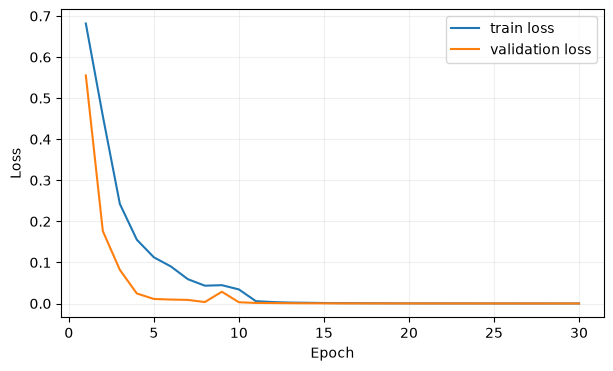

In [15]:
# Plot learning curves.
epochs = [x['epoch'] + 1 for x in history]
plt.figure(figsize=(7, 4))
plt.plot(epochs, [x['train_loss'] for x in history], label='train loss')
plt.plot(epochs, [x['val_loss'] for x in history], label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# Step 7 - Final held-out test evaluation

Only now, after the best checkpoint has been chosen from validation performance, load it and evaluate once on the test set.


In [16]:
model.load_state_dict(best_model_state)
test_metrics = evaluate(model, criterion, test_loader, device, conf)

print('Best validation epoch:', best_epoch + 1)
print('Final test metrics:')
for key, value in test_metrics.items():
    print(f'  {key}: {value:.4f}')


Best validation epoch: 3
Final test metrics:
  auc: 0.9342
  acc: 88.3721
  f1: 0.8668
  loss: 0.2804
  ce_loss: 0.2804


# Step 8 -  Inspect Attention on One Slide

Attention is useful for understanding which instances contribute strongly to the learned bag representation, but attention weights should not automatically be interpreted as causal explanations.


In [17]:
one_batch = mil_collate_fn([test_data[0]])
model.eval()
with torch.no_grad():
    logits, attention = model(
        one_batch['input'].to(device, dtype=torch.float32),
        return_attention=True, mask=one_batch['mask'].to(device),
    )

print('Slide:', one_batch['slide_id'][0])
print('Predicted class:', int(logits.argmax(dim=1)[0]))
print('Attention shape:', tuple(attention.shape))
print('Attention sum for first slide:', float(attention[0].sum()))

Slide: test_001
Predicted class: 1
Attention shape: (1, 1, 17294)
Attention sum for first slide: 0.9999999403953552


## Visualize Attention on Whole-Slide Images (WSIs)

Before running the attention visualization, please complete the following steps:

1. Visit the [ECE1512-WSI-Feature dataset on Hugging Face](https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature)

2. Download the original WSIs `test_067.tif` and `test_068.tif` and the corresponding tumor annotation file `test_068.xml`.

3. Create a folder named `slide/` under your project directory and place the downloaded files in this folder.

Run this cell after training and final test evaluation, with `DATASET = 'C16'`. It restores `best_model_state` and plots the two slides in `PROJECT_DIR/slide`:

- **test_068 (tumor):** attention overlay and green contours from `test_068.xml`, including a zoom of the annotated region.
- **test_067 (normal):** attention overlay without annotation contours, including a zoom around the highest-attention patch.

The blue rectangle marks the zoom shown on the right. Colors show **attention percentiles within each slide**, not patch tumor probabilities; areas without extracted patches stay transparent. The displayed `P(tumor)` is the model's slide-level prediction.

HDF5 patch coordinates and XML contour coordinates are assumed to be expressed in level-0 `(x, y)`  coordinates; patch coordinates are treated as top-left corners. The function parameter `patch_size_level0=512` is an editable **assumption** for the patch footprint because these HDF5 files do not store patch-size metadata. Match it to the feature extractor's patch size for an exact footprint. All visualization functions are in `wsi_visualization.py`; the cell below only calls `visualize_wsi_attention`.

[OpenSlide Python](https://openslide.org/api/python/) reads a thumbnail and a pyramid-level crop rather than loading the full-resolution WSI into memory. If dependencies are missing, run `%pip install openslide-python openslide-bin` and restart the kernel if needed. Raw per-patch attention and coordinates are retained in `attention_visualizations`.


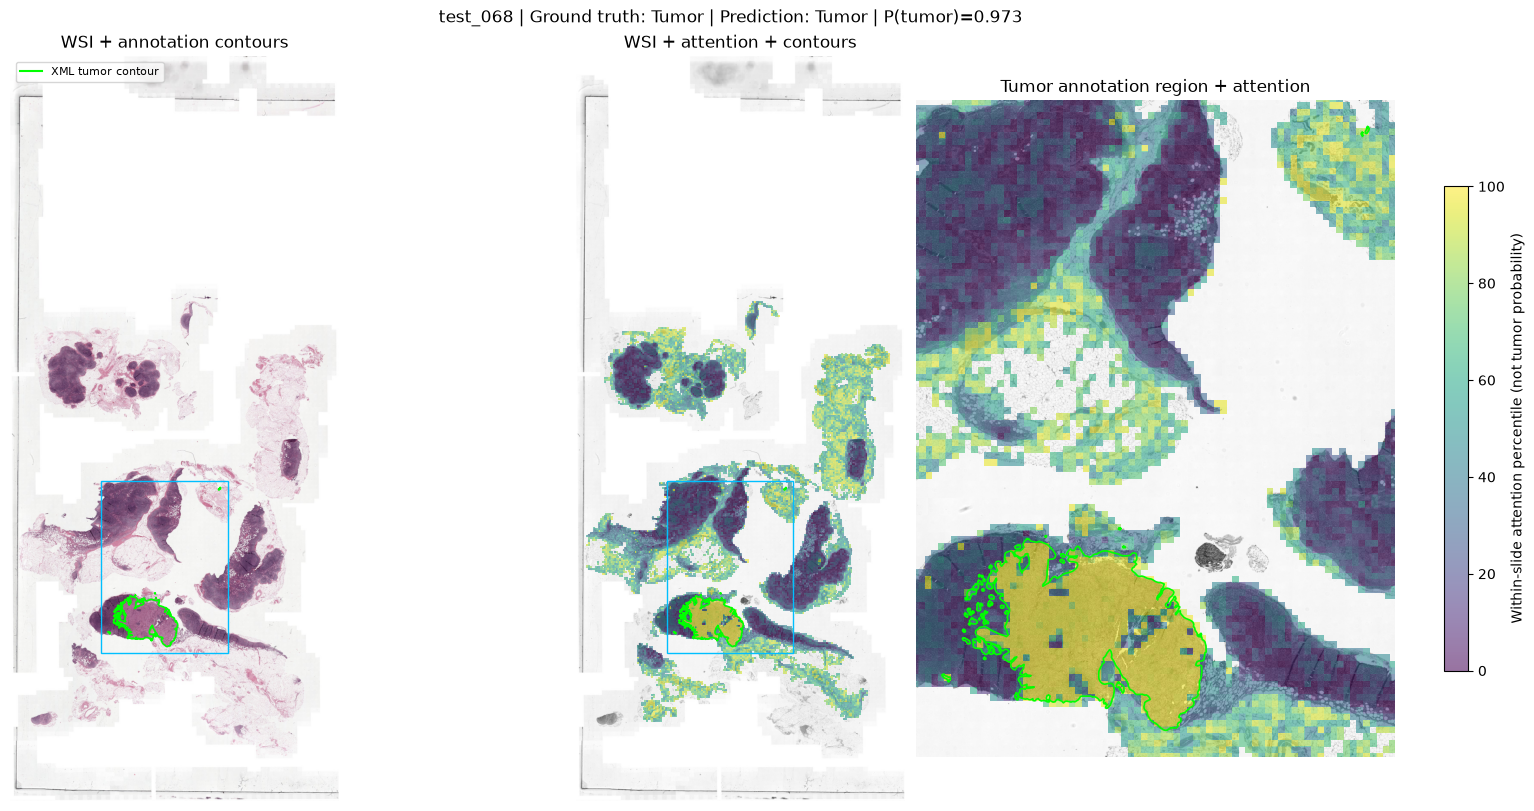

test_068: 15,037 patches; attention sum=1.000000; 45 annotation contours


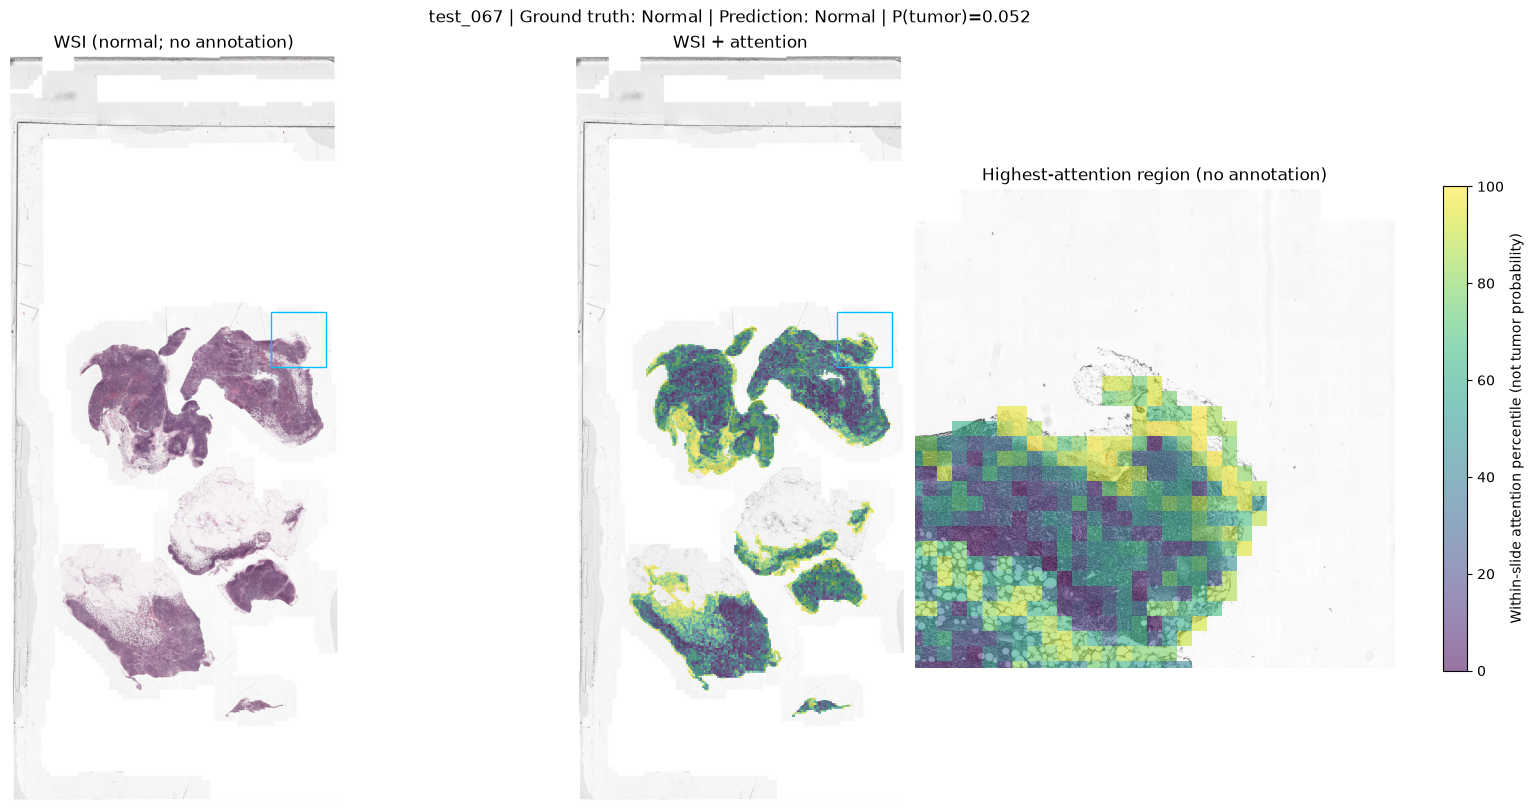

test_067: 11,926 patches; attention sum=1.000000; 0 annotation contours (no XML available)


In [18]:
# Review-copy overlays are separate from the final report figures.
if DATASET == 'C16':
    attention_visualizations = visualize_wsi_attention(
        model, conf, PROJECT_DIR, best_model_state,
        output_dir=Path(PROJECT_DIR) / 'output/notebook_figures')

# Step 9 - Research extension: propose two ideas, implement one of them

After completing the ABMIL baseline, propose **two distinct research ideas**. Select **one** for implementation and evaluation on **CAMELYON16 (C16), CAMELYON17 (C17), and BRACS**. You may explore explainability, more advanced model structures, improved objectives beyond cross-entropy, or another well-motivated direction.

**A negative result will not be penalized if the design choices, experiments, observations, and possible reasons for failure are well justified.** Report evidence relevant to your hypothesis: an explainability idea, for example, needs an explanation evaluation in addition to classification results.

Feel free to contact your TA to discuss your research ideas.

In [ ]:
# Proposal 1 (implemented): focal loss, gamma=2, no alpha, same ABMIL and split.
# Proposal 2 (design only): coordinate-neighbor smoothing of attention scores.
from training import FocalLoss
from run_experiments import run_experiment

# This complete six-run experiment saves checkpoints, histories, splits and predictions.
all_results = []
for dataset_name in ('C16', 'C17', 'BRACS'):
    for method_name in ('baseline', 'focal'):
        result_path = Path(PROJECT_DIR) / 'results' / f'{dataset_name}_{method_name}_seed42' / 'metrics.json'
        if result_path.exists():
            import json
            result = json.loads(result_path.read_text(encoding='utf8'))
        else:
            result = run_experiment(dataset_name, method_name, seed=42)
        all_results.append(result)
        print(dataset_name, method_name, result['test'])

C16 baseline {'auc': 0.9341836734693878, 'acc': 88.37209302325581, 'f1': 0.8667814113597245, 'loss': 0.28042836616523276, 'ce_loss': 0.28042836616523276}
C16 focal {'auc': 0.9535714285714285, 'acc': 91.47286821705427, 'f1': 0.9091374783889351, 'loss': 0.06459150175302698, 'ce_loss': 0.3474836722882681}
C17 baseline {'auc': 0.8196246521202353, 'acc': 76.0, 'f1': 0.5501071603605259, 'loss': 0.7938925744082371, 'ce_loss': 0.7938925744082371}
C17 focal {'auc': 0.8114629554989896, 'acc': 75.0, 'f1': 0.49680965307130437, 'loss': 0.4243906777678028, 'ce_loss': 0.6971932485699653}
BRACS baseline {'auc': 0.8042104302818588, 'acc': 39.53488372093023, 'f1': 0.34944535679829797, 'loss': 1.4265434627399542, 'ce_loss': 1.4265434627399542}
BRACS focal {'auc': 0.8113554184982756, 'acc': 40.69767441860465, 'f1': 0.36737800771414214, 'loss': 0.8999428238626552, 'ce_loss': 1.3640607630963935}


## Verify test metrics against the saved baseline

Compare the test metrics computed in this notebook with the saved baseline results for the same dataset and random seed. Each metric must agree within a tolerance of 1e-6.

In [20]:
import json
reference_path = Path(PROJECT_DIR) / 'results' / f'{DATASET}_baseline_seed{conf.seed}' / 'metrics.json'
reference = json.loads(reference_path.read_text())['test']
print('Notebook test metrics:', test_metrics)
print('Archived CLI test metrics:', reference)
for key in ('auc', 'acc', 'f1', 'ce_loss'):
    assert abs(test_metrics[key] - reference[key]) < 1e-6, (key, test_metrics[key], reference[key])
print('Full notebook execution and archived-baseline agreement passed.')

Notebook test metrics: {'auc': 0.9341836734693878, 'acc': 88.37209302325581, 'f1': 0.8667814113597245, 'loss': 0.28042836616523276, 'ce_loss': 0.28042836616523276}
Archived CLI test metrics: {'auc': 0.9341836734693878, 'acc': 88.37209302325581, 'f1': 0.8667814113597245, 'loss': 0.28042836616523276, 'ce_loss': 0.28042836616523276}
Full notebook execution and archived-baseline agreement passed.
